### Cat vs Dog Image Classification by Fine Tuning

#### Importing Modules

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import random
import os 
from PIL import Image
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix
import tensorflow as tf 
import keras 
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPool2D,Flatten,Dense,GlobalAveragePooling2D,BatchNormalization,Dropout 
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau,ModelCheckpoint
from tensorflow.keras.applications import MobileNetV2 
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

#### Setting Seed

In [2]:
SEED=32
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

#### Setting Constants

In [3]:
DATA_DIR="PetImages"
IMG_SIZE=(224,224)
BATCH_SIZE=64
LABEL_MAP={}
for i,class_name in enumerate(os.listdir(DATA_DIR)):
    LABEL_MAP[class_name]=i
print(LABEL_MAP)

{'Cat': 0, 'Dog': 1}


#### 

#### Reading Files

In [4]:
image_paths=[]
labels=[]
for class_name,class_label in LABEL_MAP.items():
    class_dir=os.path.join(DATA_DIR,class_name)
    for image in os.listdir(class_dir):
        img_path=os.path.join(class_dir,image)
        image_paths.append(img_path)
        labels.append(class_label)
print(f"Sample Image path: {image_paths[15]} and label: {labels[15]}")

Sample Image path: PetImages\Cat\1001.jpg and label: 0


#### Creating DataFrame

In [5]:
df=pd.DataFrame({
    'image':image_paths,
    'label':labels
})
df.head()

,image,label
0,PetImages\Cat\0.jpg,0
1,PetImages\Cat\1.jpg,0
2,PetImages\Cat\10.jpg,0
3,PetImages\Cat\100.jpg,0
4,PetImages\Cat\1000.jpg,0


In [6]:
print(f"Total number of images: {len(df)} images.")

Total number of images: 24998 images.


#### Removing Corrupted Images

In [7]:
valid_imgs=[]
for image in df['image']:
    try:
        with Image.open(image) as img:
            img.verify()
        valid_imgs.append(image)
    except Exception:
        print(f"Invalid Image: {image}")
print(f"Total number of valid images: {len(valid_imgs)} out of {len(df)} images.")

Total number of valid images: 24998 out of 24998 images.


In [8]:
df=df[df['image'].isin(valid_imgs)].reset_index(drop=True)
print("Number of images after removing invalid ones:",len(df))

Number of images after removing invalid ones: 24998


#### Shuffling DataFrame

In [9]:
df=df.sample(frac=1,random_state=SEED)
df.head()

,image,label
24062,PetImages\Dog\9156.jpg,1
11937,PetImages\Cat\9493.jpg,0
24892,PetImages\Dog\9903.jpg,1
4753,PetImages\Cat\3025.jpg,0
24968,PetImages\Dog\9972.jpg,1


#### Checking Class Balance

In [10]:
df['label'].value_counts()

label
1    12499
0    12499
Name: count, dtype: int64

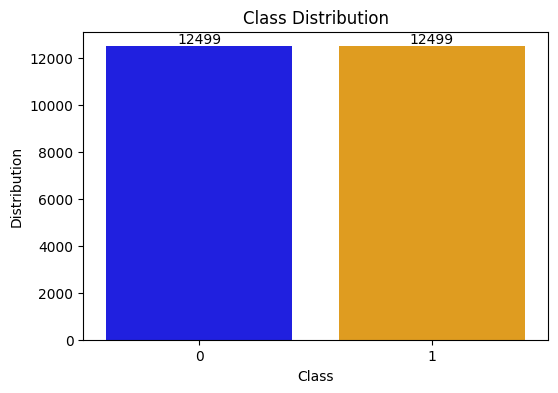

In [11]:
plt.figure(figsize=(6,4))
ax=sns.countplot(x=df['label'],hue=df['label'],legend=False,palette=['blue','orange'])
for container in ax.containers:
    ax.bar_label(container)
plt.xlabel("Class")
plt.ylabel("Distribution")
plt.title("Class Distribution")
plt.show()

#### Displaying 25 sample images and corresponding labels

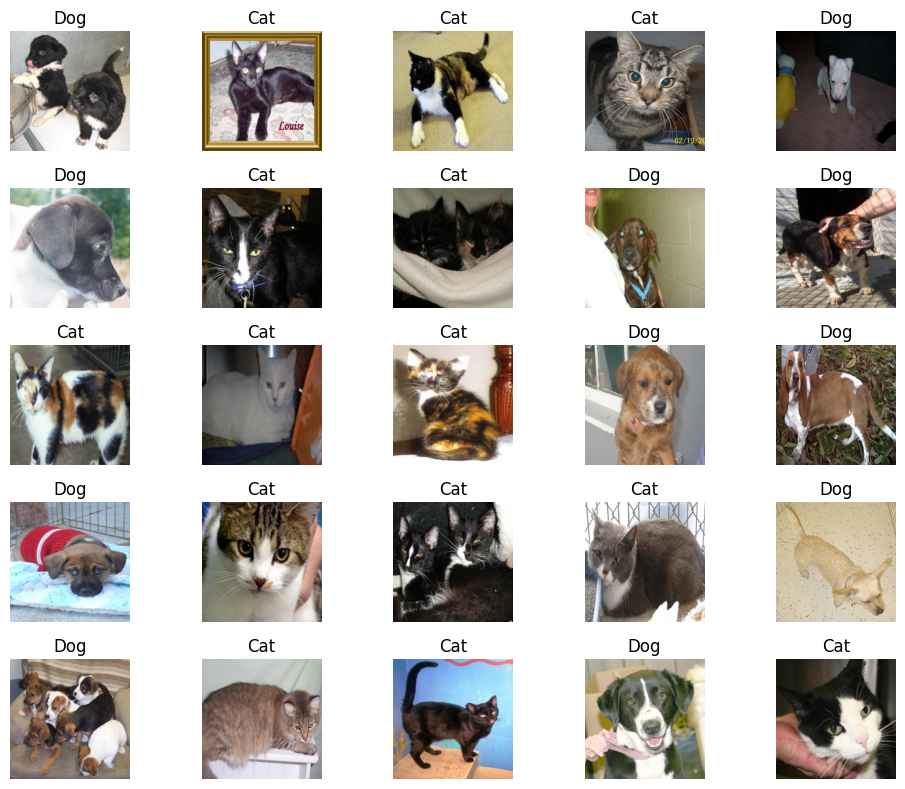

In [12]:
plt.figure(figsize=(10,8))
sample_df=df.sample(25,random_state=SEED)
for i,(_,row) in enumerate(sample_df.iterrows()):
    image_path=row['image']
    true_label=row['label']
    image=Image.open(image_path).convert('RGB').resize(IMG_SIZE)
    plt.subplot(5,5,i+1)
    plt.imshow(image)
    plt.title({v:k for k,v in LABEL_MAP.items()}[true_label])
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Creating Data Generators

In [13]:
train_data_gen=ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.1,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode='reflect'
)

In [14]:
val_test_data_gen=ImageDataGenerator(
    preprocessing_function=preprocess_input
)

#### Plotting before and after augmentation

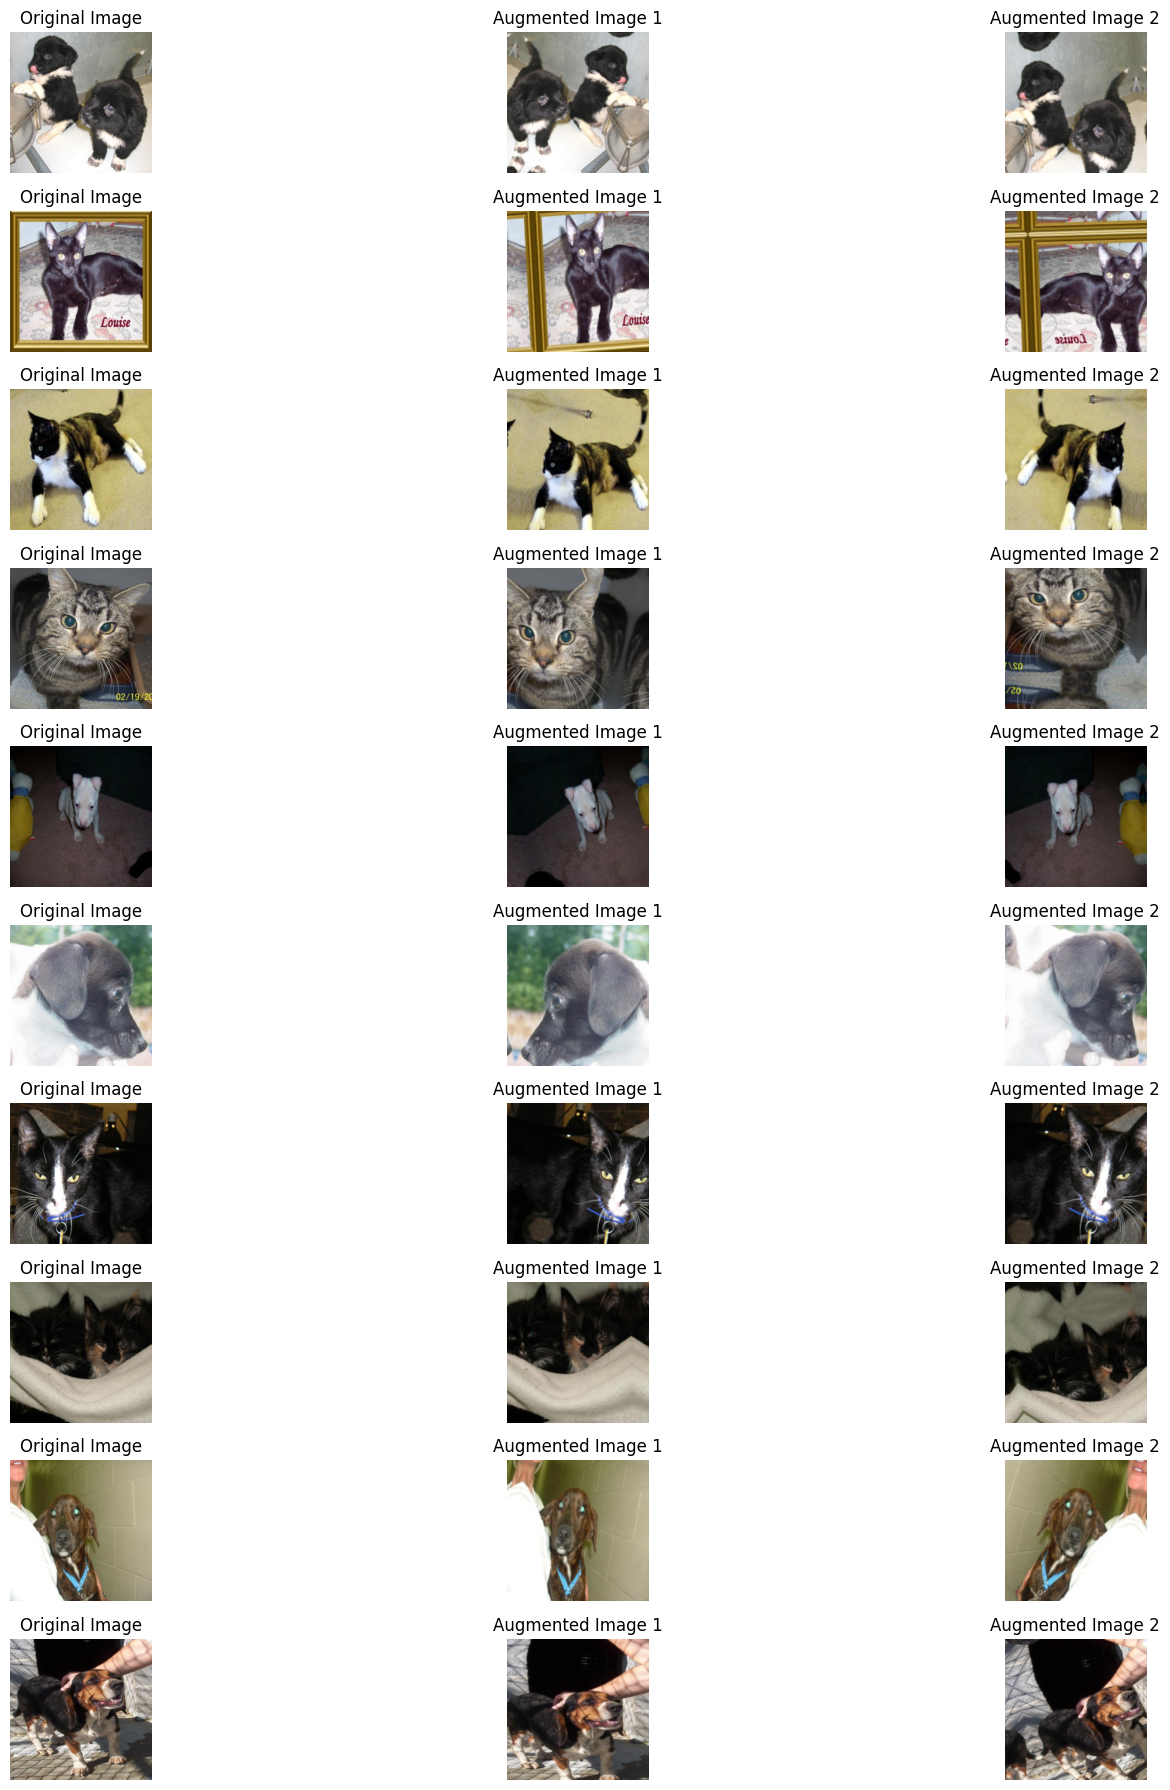

In [15]:
plt.figure(figsize=(18,18))
sample_df=df.sample(10,random_state=SEED)
for i,image in enumerate(sample_df['image']):
    image=Image.open(image).convert('RGB').resize(IMG_SIZE)
    plt.subplot(10,3,3*i+1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis('off')
    image=np.array(image)
    augmented_image=train_data_gen.random_transform(image)
    plt.subplot(10,3,3*i+2)
    plt.imshow(augmented_image)
    plt.title("Augmented Image 1")
    plt.axis('off')
    augmented_image2=train_data_gen.random_transform(image)
    plt.subplot(10,3,3*i+3)
    plt.imshow(augmented_image2)
    plt.title("Augmented Image 2")
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Fixing Datatypes

In [16]:
df['label']=df['label'].astype(str)

#### Creating Splits

In [17]:
train_df,temp_df=train_test_split(df,test_size=0.3,random_state=SEED,stratify=df['label'])
val_df,test_df=train_test_split(temp_df,test_size=0.5,random_state=SEED,stratify=temp_df['label'])
print(f"Train size: {len(train_df)}")
print(f"Val size: {len(val_df)}")
print(f"Test size: {len(test_df)}")

Train size: 17498
Val size: 3750
Test size: 3750


#### Creating Iterators

In [18]:
train_iterator=train_data_gen.flow_from_dataframe(
    train_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=SEED
)

Found 17498 validated image filenames belonging to 2 classes.


In [19]:
val_iterator=val_test_data_gen.flow_from_dataframe(
    val_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 3750 validated image filenames belonging to 2 classes.


In [20]:
test_iterator=val_test_data_gen.flow_from_dataframe(
    test_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 3750 validated image filenames belonging to 2 classes.


#### Creating Model

We will do 2 phases: phase 1 will be only adding classfication head, while in phase 2 we unfreeze the top layers and fine tune

#### Phase 1

In [21]:
#Phase 1: Dont unfreeze, only add classification head
base_model=MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE,3)
)
base_model.trainable=False

In [22]:
model=Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.4),
    Dense(256,activation='relu'),
    Dropout(0.4),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(1,activation='sigmoid'),
])

In [23]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,618,945 (9.99 MB)

 Trainable params: 360,961 (1.38 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
opt=keras.optimizers.Adam(learning_rate=1e-3)
model.compile(optimizer=opt,loss='binary_crossentropy',metrics=['accuracy'])

In [25]:
lr_scheduler=ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6
)

In [26]:
early_stop=EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [27]:
checkpoint=ModelCheckpoint(
    "best_finetuned_model.keras",
    monitor='val_loss',
    save_best_only=True
)

In [28]:
history=model.fit(train_iterator,epochs=10,validation_data=val_iterator,callbacks=[lr_scheduler,early_stop,checkpoint])

Epoch 1/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 310s 1s/step - accuracy: 0.9595 - loss: 0.1114 - val_accuracy: 0.9869 - val_loss: 0.0358 - learning_rate: 0.0010
Epoch 2/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 353s 1s/step - accuracy: 0.9733 - loss: 0.0752 - val_accuracy: 0.9851 - val_loss: 0.0377 - learning_rate: 0.0010
Epoch 3/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 417s 2s/step - accuracy: 0.9752 - loss: 0.0647 - val_accuracy: 0.9869 - val_loss: 0.0350 - learning_rate: 0.0010
Epoch 4/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 444s 2s/step - accuracy: 0.9753 - loss: 0.0642 - val_accuracy: 0.9859 - val_loss: 0.0317 - learning_rate: 0.0010
Epoch 5/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 441s 2s/step - accuracy: 0.9794 - loss: 0.0562 - val_accuracy: 0.9888 - val_loss: 0.0301 - learning_rate: 0.0010
Epoch 6/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 391s 1s/step - accuracy: 0.9774 - loss: 0.0599 - val_accuracy: 0.9864 - val_loss: 0.0338 - learning_rate: 0.0010
Epoch 7/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 396s 1s/step - accuracy: 0.9808 - loss: 0.

#### Phase 2

In [29]:
#Phase 2: Unfreeze top 30 layers and Fine tune
base_model.trainable=True
for layer in base_model.layers[:-30]:
    layer.trainable=False 
#we wont unfreeze the batch normalization layers
for layer in base_model.layers[-30:]:
    if isinstance(layer,BatchNormalization):
        layer.trainable=False

In [30]:
opt=keras.optimizers.Adam(learning_rate=1e-5)
model.compile(optimizer=opt,loss='binary_crossentropy',metrics=['accuracy'])

In [31]:
lr_scheduler=ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7
)

In [32]:
history=model.fit(train_iterator,epochs=15,validation_data=val_iterator,callbacks=[lr_scheduler,early_stop,checkpoint])

Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 576s 2s/step - accuracy: 0.9818 - loss: 0.0477 - val_accuracy: 0.9891 - val_loss: 0.0278 - learning_rate: 1.0000e-05
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 622s 2s/step - accuracy: 0.9850 - loss: 0.0405 - val_accuracy: 0.9899 - val_loss: 0.0269 - learning_rate: 1.0000e-05
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 648s 2s/step - accuracy: 0.9855 - loss: 0.0403 - val_accuracy: 0.9880 - val_loss: 0.0288 - learning_rate: 1.0000e-05
Epoch 4/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 677s 2s/step - accuracy: 0.9869 - loss: 0.0371 - val_accuracy: 0.9891 - val_loss: 0.0257 - learning_rate: 1.0000e-05
Epoch 5/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 664s 2s/step - accuracy: 0.9868 - loss: 0.0353 - val_accuracy: 0.9909 - val_loss: 0.0254 - learning_rate: 1.0000e-05
Epoch 6/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 568s 2s/step - accuracy: 0.9876 - loss: 0.0335 - val_accuracy: 0.9885 - val_loss: 0.0261 - learning_rate: 1.0000e-05
Epoch 7/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 499s 2s/step - acc

#### Test Data Evaluation

In [33]:
test_results=model.evaluate(test_iterator,return_dict=True)
print(test_results)

59/59 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.9904 - loss: 0.0228
{'accuracy': 0.9904000163078308, 'loss': 0.02277841418981552}


#### Accuracy and Loss Curves

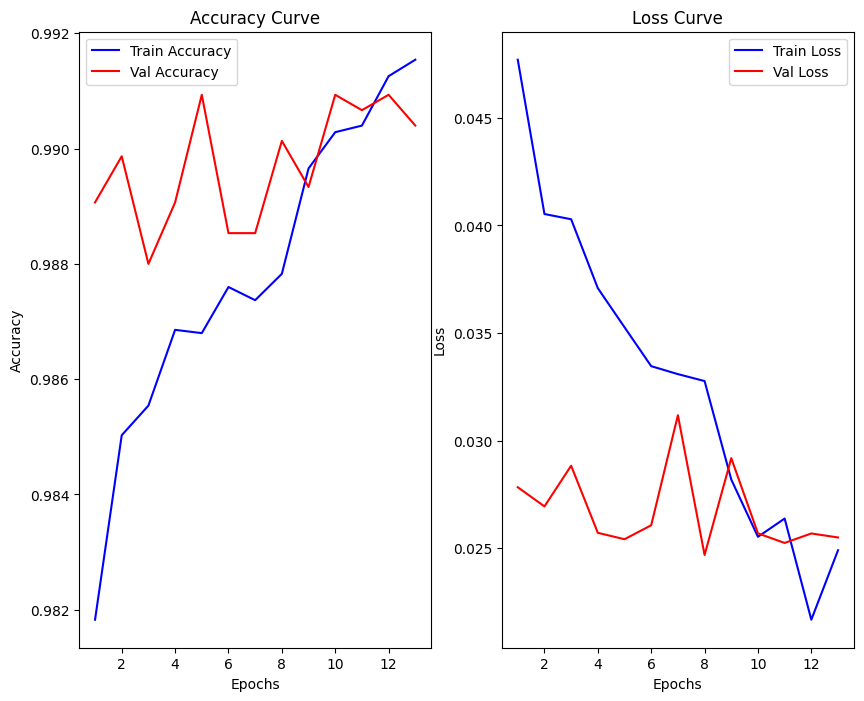

In [34]:
plt.figure(figsize=(10,8))
train_acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
train_loss=history.history['loss']
val_loss=history.history['val_loss']
epochs=range(1,len(train_acc)+1)
plt.subplot(1,2,1)
plt.plot(epochs,train_acc,'b',label="Train Accuracy")
plt.plot(epochs,val_acc,'r',label="Val Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()
plt.subplot(1,2,2)
plt.plot(epochs,train_loss,'b',label="Train Loss")
plt.plot(epochs,val_loss,'r',label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()
plt.show()

#### Confusion Matrix

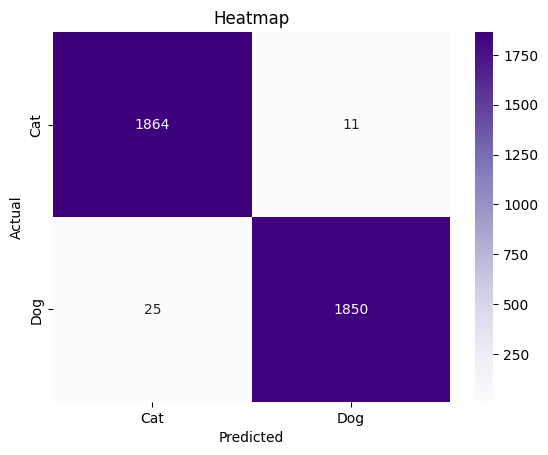

In [35]:
y_true=test_iterator.classes
y_pred_prob=model.predict(test_iterator, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)
cm=confusion_matrix(y_true,y_pred,labels=[0,1])
sns.heatmap(cm,annot=True,cmap='Purples',fmt='d',xticklabels=['Cat','Dog'],yticklabels=['Cat','Dog'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Heatmap")
plt.show()

#### Classification Report

In [36]:
print(classification_report(y_true,y_pred,labels=[0,1],target_names=['Cat','Dog']))

              precision    recall  f1-score   support

         Cat       0.99      0.99      0.99      1875
         Dog       0.99      0.99      0.99      1875

    accuracy                           0.99      3750
   macro avg       0.99      0.99      0.99      3750
weighted avg       0.99      0.99      0.99      3750



#### Sample Images

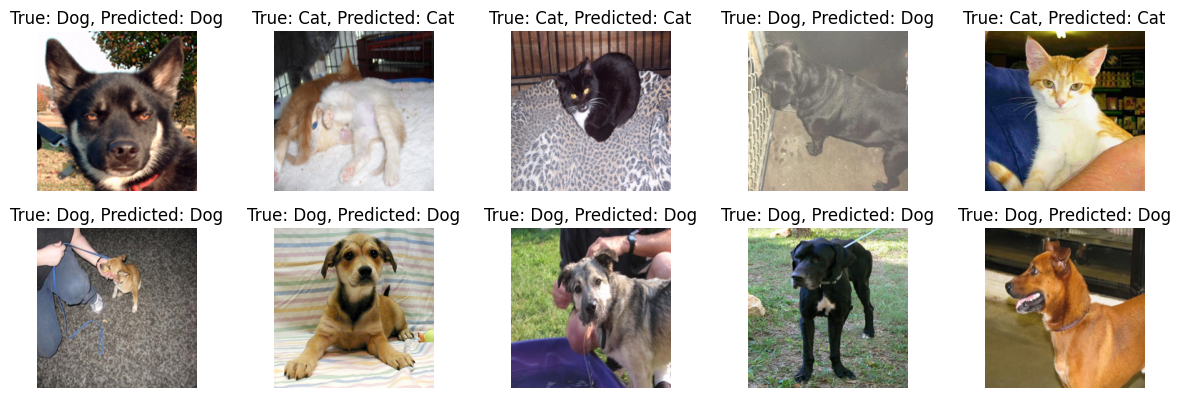

In [37]:
plt.figure(figsize=(12,10))
sample_df2=test_df.sample(10,random_state=SEED)
for i,(_,row) in enumerate(sample_df2.iterrows()):
    image_path=row['image']
    true_label=row['label']
    image=Image.open(image_path).convert('RGB').resize(IMG_SIZE)
    plt.subplot(5,5,i+1)
    plt.imshow(image)
    true_label={str(v):k for k,v in LABEL_MAP.items()}[true_label]
    image=np.array(image,dtype=np.float32)
    image=preprocess_input(image)
    image = np.expand_dims(image, axis=0)
    pred_prob = model.predict(image, verbose=0)[0][0]
    pred_label = "Dog" if pred_prob >= 0.5 else "Cat"
    plt.title(f"True: {true_label}, Predicted: {pred_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Visualizing Wrong Predictions

creating dataframe for wrong predictions

In [38]:
wrong_df=pd.DataFrame(columns=['image','label','prediction'])
for _,row in test_df.iterrows():
    image_path=row['image']
    image_true_label=row['label']
    image_true_label = {str(v): k for k, v in LABEL_MAP.items()}[image_true_label]
    image=Image.open(image_path).convert('RGB').resize(IMG_SIZE)
    image=np.array(image,dtype=np.float32)
    image=preprocess_input(image)
    image = np.expand_dims(image, axis=0)
    image_pred_prob=model.predict(image,verbose=0)[0][0]
    image_pred_label="Dog" if image_pred_prob>=0.5 else "Cat"
    if(image_true_label!=image_pred_label):
        wrong_df.loc[len(wrong_df)]=[image_path,image_true_label,image_pred_label]
print(f"Number of wrong predictions: {len(wrong_df)} out of {len(test_df)} predictions.")

Number of wrong predictions: 28 out of 3750 predictions.


In [39]:
wrong_df.head()

,image,label,prediction
0,PetImages\Cat\2939.jpg,Cat,Dog
1,PetImages\Dog\9221.jpg,Dog,Cat
2,PetImages\Dog\2507.jpg,Dog,Cat
3,PetImages\Dog\5487.jpg,Dog,Cat
4,PetImages\Cat\6464.jpg,Cat,Dog


displaying wrong predictions

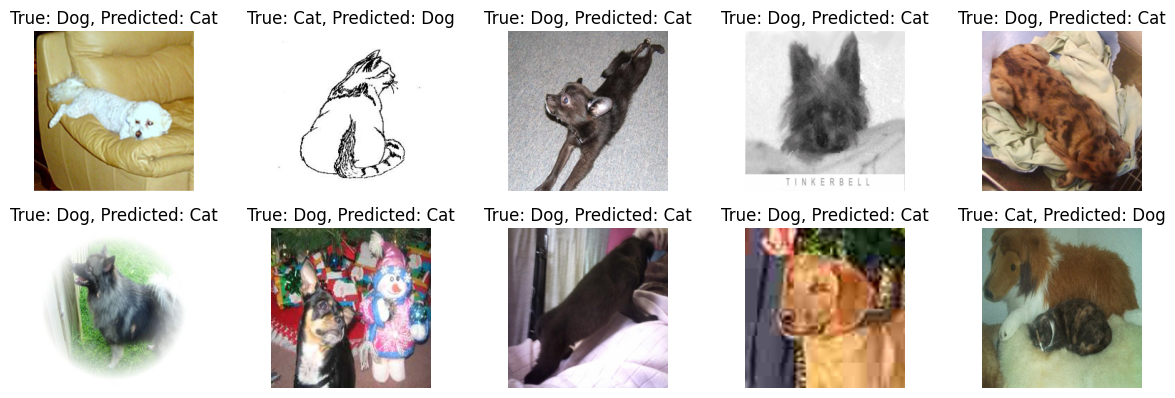

In [40]:
plt.figure(figsize=(12,10))
sample_df2=wrong_df.sample(min(10,len(wrong_df)),random_state=SEED)
for i,(_,row) in enumerate(sample_df2.iterrows()):
    image_path=row['image']
    true_label=row['label']
    pred_label=row['prediction']
    image=Image.open(image_path).convert('RGB').resize(IMG_SIZE)
    plt.subplot(5,5,i+1)
    plt.imshow(image)
    plt.title(f"True: {true_label}, Predicted: {pred_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()